In [1]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


In [2]:
# Load Titanic dataset
df = sns.load_dataset("titanic")

# Display first five rows
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [3]:
df = df[["survived", "pclass", "sex", "age", "fare"]]

print(df.head())

   survived  pclass     sex   age     fare
0         0       3    male  22.0   7.2500
1         1       1  female  38.0  71.2833
2         1       3  female  26.0   7.9250
3         1       1  female  35.0  53.1000
4         0       3    male  35.0   8.0500


In [4]:
# Check missing values
print(df.isnull().sum())

# Remove missing values
df = df.dropna()

# Convert gender into numerical values
# Female = 1, Male = 0
df["sex"] = (df["sex"] == "female").astype(int)

# Display cleaned dataset
print(df.head())

print("\nDataset shape:", df.shape)

survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64
   survived  pclass  sex   age     fare
0         0       3    0  22.0   7.2500
1         1       1    1  38.0  71.2833
2         1       3    1  26.0   7.9250
3         1       1    1  35.0  53.1000
4         0       3    0  35.0   8.0500

Dataset shape: (714, 5)


In [5]:
# Features
X = df.drop(columns="survived")

# Target
y = df["survived"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   pclass  sex   age     fare
0       3    0  22.0   7.2500
1       1    1  38.0  71.2833
2       3    1  26.0   7.9250
3       1    1  35.0  53.1000
4       3    0  35.0   8.0500

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (571, 4)
Testing data: (143, 4)


In [7]:
baseline = max(y_test.mean(), 1 - y_test.mean())

print("Baseline Accuracy:", round(baseline, 3))

Baseline Accuracy: 0.594


In [8]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [9]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)

Predicted Values:
[1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 1
 0 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 1 1 0 1 0
 0 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0
 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 1 0 1 0 1 1 1 1 0 0 0 1 0 0 1]

Actual Values:
[1 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 1 0 1 1 0 1 1
 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1 0 0 0
 0 0 1 0 0 1 0 0 1 1 1 0 0 1 1 0 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 0 0 1 0 0 0 1 1 0 0 0 1 0 0 0]


In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("Baseline Accuracy:", round(baseline, 3))
print("Model Accuracy:", round(accuracy, 3))

Baseline Accuracy: 0.594
Model Accuracy: 0.797


In [11]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[72 13]
 [16 42]]


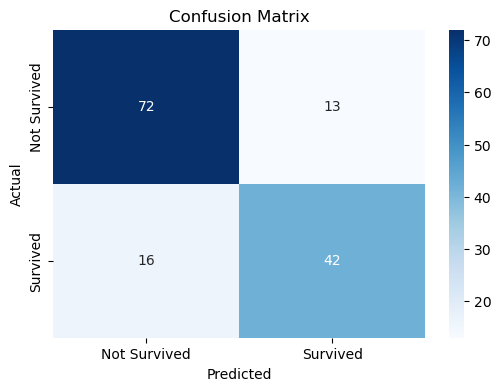

In [12]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [13]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352


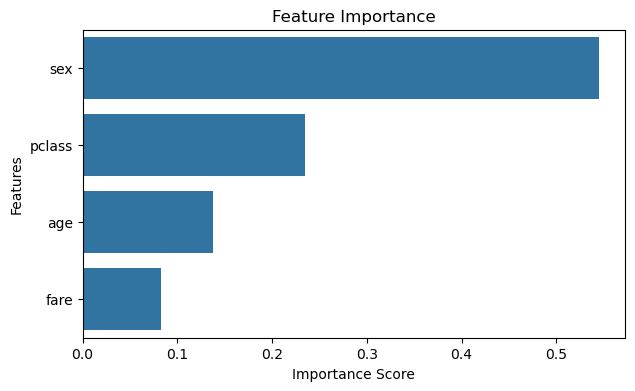

In [14]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [15]:
train_accuracy = []
test_accuracy = []

depths = range(1, 13)

for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)

    train_accuracy.append(
        accuracy_score(y_train, train_pred)
    )

    test_accuracy.append(
        accuracy_score(y_test, test_pred)
    )

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: [0.7793345008756567, 0.7950963222416813, 0.8178633975481612, 0.8476357267950964, 0.8651488616462347, 0.882661996497373, 0.9159369527145359, 0.9246935201401051, 0.9474605954465849, 0.9562171628721541, 0.9649737302977233, 0.968476357267951]
Testing Accuracy: [0.7832167832167832, 0.7762237762237763, 0.8111888111888111, 0.7972027972027972, 0.7622377622377622, 0.7832167832167832, 0.7832167832167832, 0.7902097902097902, 0.7692307692307693, 0.7622377622377622, 0.7692307692307693, 0.7762237762237763]


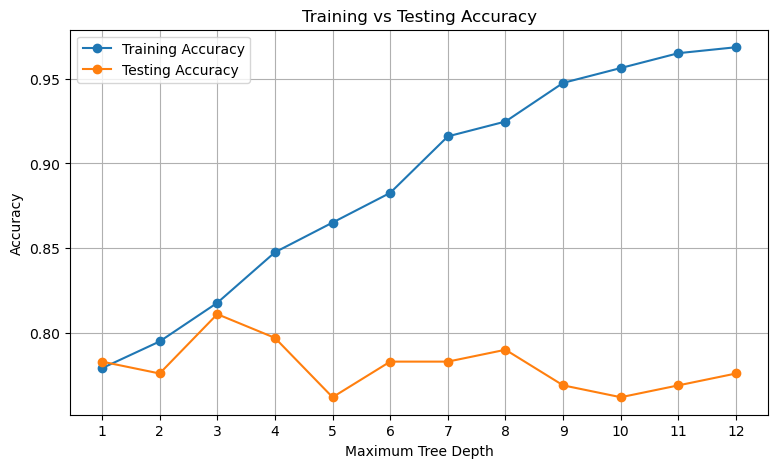

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    train_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_accuracy,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.title("Training vs Testing Accuracy")

plt.xticks(depths)
plt.legend()
plt.grid(True)

plt.show()

In [17]:
print("========== PROJECT SUMMARY ==========")

print("Project: Titanic Survival Prediction")
print("Algorithm: Decision Tree Classifier")
print("Dataset: Titanic")

print("Baseline Accuracy:", round(baseline, 3))
print("Model Accuracy:", round(accuracy, 3))

if accuracy > baseline:
    print("Result: Model performed better than baseline.")
else:
    print("Result: Model did not beat the baseline.")

print("\nMost Important Feature:")
print(feature_importance.iloc[0]["Feature"])

print("\nProject Completed Successfully!")

========== PROJECT SUMMARY ==========
Project: Titanic Survival Prediction
Algorithm: Decision Tree Classifier
Dataset: Titanic
Baseline Accuracy: 0.594
Model Accuracy: 0.797
Result: Model performed better than baseline.

Most Important Feature:
sex

Project Completed Successfully!
